# Questão 4 — filtros, ativações e análise de previsões da CNN

Este notebook apresenta a análise da CNN **com dropout**, com accuracy de teste 74,56%. Para funcionar em uma sessão nova, inclui o carregamento, as arquiteturas e o treinamento de apoio da Q3 antes das visualizações. Isso repete treinamento se a Q3 já tiver sido executada em outro notebook. Os pesos não estão embutidos no `.ipynb`; as figuras e métricas da execução original estão salvas.

## Como estudar este notebook

O texto acompanha três pilares: **dados** (o que representa cada exemplo e como foi preparado), **arquitetura** (como a rede transforma entradas em respostas) e **resultados** (o que a avaliação permite concluir). Antes de cada célula há uma explicação de suas operações, decisões e saídas esperadas. As saídas já salvas permitem ler o trabalho sem executar novos treinamentos.

**Estado dos resultados.** As células de código e suas saídas foram preservadas da execução fornecida. Esta revisão acrescenta documentação; não executa novos experimentos. Uma saída salva é um registro do experimento, não mantém os modelos Python vivos na memória. Para utilizar variáveis ou gerar novas previsões no Colab, execute as células em ordem. Versões, dispositivo e operações aleatórias podem causar diferenças em uma nova execução. Os números descritos no texto são os da execução registrada e devem ser revistos se os modelos forem retreinados.

### Fundamentos necessários para acompanhar as células

- **Exemplo ou observação:** uma entrada acompanhada da resposta conhecida. Um lote reúne vários exemplos para uma atualização dos pesos.
- **Atributo:** uma informação de entrada. O **alvo** é aquilo que queremos prever. Atributos não devem conter a própria resposta ou informações indisponíveis no momento de prever.
- **Neurônio e camada densa:** cada neurônio calcula uma combinação ponderada das entradas, soma um viés e aplica uma ativação. Em uma camada densa, cada neurônio recebe todas as saídas da camada anterior. Pesos e vieses são os parâmetros aprendidos.
- **Ativação:** introduz uma transformação não linear. ReLU calcula `max(0, x)`; Tanh é suave e varia de −1 a 1; Sigmoid varia de 0 a 1. Uma saída linear não impõe esses limites. A escolha depende da tarefa e deve ser avaliada no contexto do treinamento.
- **Função de perda:** transforma a diferença entre resposta e previsão em um número a minimizar. Uma métrica de avaliação pode coincidir com a perda, mas também pode medir outro aspecto do desempenho.
- **Gradiente e retropropagação:** o gradiente indica como a perda varia em relação a cada parâmetro. A retropropagação calcula esses gradientes ao percorrer as operações da rede em sentido inverso.
- **Adam:** otimizador que usa estimativas acumuladas dos gradientes e de seus quadrados para atualizar os parâmetros. A taxa de aprendizado controla a escala dos ajustes. Adam e retropropagação cumprem funções complementares.
- **Época:** uma passagem pelos exemplos de treino. **Batch size** é a quantidade de exemplos em cada lote. Mais épocas aumentam o trabalho de otimização, mas não garantem melhor desempenho em dados novos.
- **Early stopping:** monitora uma perda em dados separados, espera um número de épocas sem melhora e interrompe o treinamento. Quando solicitado, restaura os pesos da melhor época monitorada. A técnica limita o sobreajuste, mas não garante eliminá-lo.
- **Semente:** controla parte da aleatoriedade, como divisão e inicialização. Repetir sementes ajuda a observar a sensibilidade do resultado; não substitui testar em amostras independentes.
- **Generalização e sobreajuste:** generalizar é manter desempenho em dados não usados para ajustar os pesos. Quando o treino melhora e a avaliação separada estagna ou piora, há indício de que parte do aprendizado deixou de se transferir.

**Como ler “média ± desvio-padrão”.** A média resume as repetições, e o desvio descreve sua dispersão. É necessário verificar se as repetições mudam a inicialização ou também a divisão dos dados. Esse símbolo não representa variação por época nem um intervalo de confiança.

## Como interpretar uma classificação

Uma classe prevista é escolhida pela maior saída da Softmax. Para cada classe, **TP** são acertos nessa classe, **FP** são exemplos de outras classes previstos como ela e **FN** são exemplos dela previstos como outra.

$$\mathrm{precision}=\frac{TP}{TP+FP},\qquad
\mathrm{recall}=\frac{TP}{TP+FN},\qquad
F1=\frac{2\,\mathrm{precision}\,\mathrm{recall}}{\mathrm{precision}+\mathrm{recall}}.$$

Precision responde “quantas previsões desta classe estavam certas?”; recall responde “quantos casos reais dela foram encontrados?”. F1 combina as duas. **Accuracy** é a proporção total de acertos. **Macro** calcula a métrica por classe e tira a média sem favorecer classes grandes; **weighted** pondera pela quantidade de exemplos. A média macro de F1 é a média dos F1 individuais, não o F1 calculado a partir de precision e recall macro.

Na matriz de confusão, linhas são classes reais e colunas são previstas. A diagonal contém acertos. A normalização por linha divide cada linha pela quantidade real da classe; sua diagonal equivale ao recall por classe. O suporte (`support` ou `n`) é o número de exemplos reais.

A **entropia cruzada** penaliza uma baixa probabilidade atribuída à classe correta: para um exemplo, a perda é $-\log p_{correta}$. A variante `sparse` aceita rótulos inteiros em vez de vetores com um indicador por classe. Uma Softmax pode gerar valor alto e estar errada; os escores não foram calibrados para garantir que 0,9 corresponda a 90% de acertos.

## Dados, arquitetura e plano de leitura

Cada imagem é uma matriz 32×32×3 e seu alvo é uma entre dez classes: avião, automóvel, pássaro, gato, veado, cachorro, sapo, cavalo, navio ou caminhão. MLP e CNN recebem os mesmos exemplos normalizados. O dado de teste fica separado do ajuste dos pesos e da parada.

A CNN impõe um **viés indutivo espacial**: sua organização favorece relações de vizinhança e pesos compartilhados. Isso é uma hipótese estrutural adequada a imagens, não uma garantia de acerto. A MLP usa conexões densas sobre o vetor de pixels. A comparação inclui arquiteturas e regularizações diferentes, portanto não é uma ablação que varie apenas um componente.

Na Q3, as saídas centrais são curvas e comparação de classificação. Na Q4, distinguimos **pesos de filtros** (parâmetros fixos após o treino), **ativações** (respostas que dependem da imagem) e **Grad-CAM** (aproximação da relevância espacial para uma classe). Essa diferença impede interpretar todas as imagens coloridas como se fossem a mesma medida.

## 1. Ambiente e reprodutibilidade

A célula importa as bibliotecas e fixa sementes de Python, NumPy e TensorFlow. `MODO_EXECUCAO="completo"` corresponde às saídas preservadas. A lista de GPUs registra o ambiente disponível; a execução salva informou CPU. O modo rascunho reduz dados/épocas e muda o experimento. Algumas importações vieram do ambiente comum do projeto e não são utilizadas neste recorte.

Fixar sementes melhora a rastreabilidade, mas não garante identidade de resultados em versões ou dispositivos diferentes. Definir `PYTHONHASHSEED` dentro de um processo já iniciado também não retroage sobre toda aleatoriedade de hash. A documentação relata o que foi executado sem prometer reprodução numérica exata.

In [1]:
import os, random, zipfile, urllib.request, io
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (mean_absolute_error, mean_squared_error, accuracy_score,
    precision_recall_fscore_support, classification_report, confusion_matrix)
from sklearn.utils.class_weight import compute_class_weight

SEMENTE=42
os.environ["PYTHONHASHSEED"]=str(SEMENTE)
random.seed(SEMENTE); np.random.seed(SEMENTE); tf.random.set_seed(SEMENTE)
MODO_EXECUCAO="completo"  # use "rascunho" durante desenvolvimento
sns.set_theme(style="whitegrid",context="notebook")
print("TensorFlow:",tf.__version__)
print("GPU(s):",tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU(s): []


## 2. Preparação dos dados

### Leitura da célula: carregar imagens e preservar a separação

CIFAR-10 fornece 50.000 imagens de treinamento e 10.000 de teste, RGB de 32×32 pixels em dez categorias. Reservamos 5.000 das primeiras para validação por divisão estratificada, ficando com 45.000/5.000/10.000. `ravel` transforma rótulos com uma coluna em um vetor; não altera classes.

Dividir os pixels por 255 transforma valores de 0–255 para [0,1]. Isso é normalização por uma constante conhecida, sem estimar média ou desvio do teste. `float32` adequa o tipo às operações da rede. O formato é `(quantidade, altura, largura, canais)`, com três canais RGB. Os exemplos iniciais apenas ilustram o dado; não são uma avaliação de qualidade.

O modo completo corresponde aos resultados salvos. O modo rascunho usa 12.000 imagens de treino e menos épocas: serve para conferir o fluxo e não deve ser apresentado como o mesmo experimento. Não há aumento artificial de dados, imagens pré-treinadas ou extração externa de características nesta execução.

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1319s 8us/step


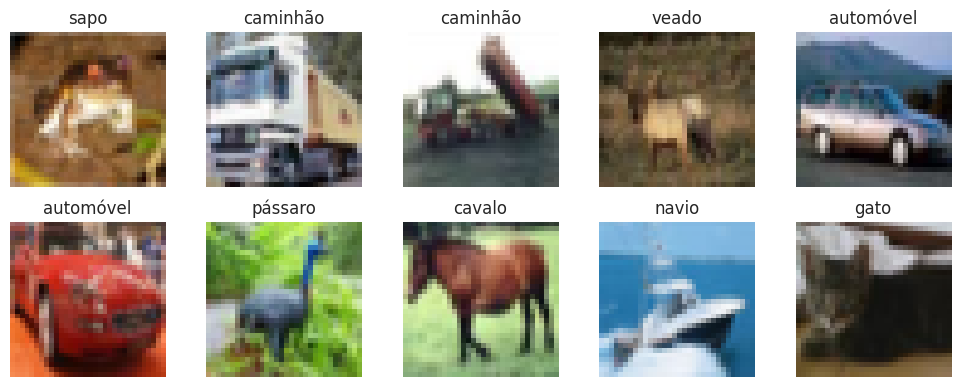

Treino / validação / teste: 45000 5000 10000


In [2]:
(x_img_train,y_img_train),(x_img_test,y_img_test)=keras.datasets.cifar10.load_data()
y_img_train=y_img_train.ravel(); y_img_test=y_img_test.ravel()
nomes_cifar=["avião","automóvel","pássaro","gato","veado","cachorro","sapo","cavalo","navio","caminhão"]
fig,axs=plt.subplots(2,5,figsize=(10,4))
for i,ax in enumerate(axs.flat): ax.imshow(x_img_train[i]); ax.set_title(nomes_cifar[y_img_train[i]]); ax.axis("off")
plt.tight_layout(); plt.show()
Xc_tr,Xc_va,yc_tr,yc_va=train_test_split(x_img_train,y_img_train,test_size=5000,random_state=SEMENTE,stratify=y_img_train)
if MODO_EXECUCAO=="rascunho": Xc_tr,_,yc_tr,_=train_test_split(Xc_tr,yc_tr,train_size=12000,random_state=SEMENTE,stratify=yc_tr)
Xc_tr=Xc_tr.astype("float32")/255.; Xc_va=Xc_va.astype("float32")/255.; Xc_te=x_img_test.astype("float32")/255.
yc_tr=yc_tr.astype("int64"); yc_va=yc_va.astype("int64"); yc_te=y_img_test.astype("int64")
print("Treino / validação / teste:",len(Xc_tr),len(Xc_va),len(Xc_te))

## 3. Arquiteturas e treinamento

### Leitura da célula: duas arquiteturas e o que cada operação faz

**MLP:** `32×32×3 → Flatten 3.072 → Densa 512 ReLU → Dropout 0,35 → Densa 256 ReLU → Dropout 0,25 → Softmax 10`. Flatten reorganiza os valores sem descartá-los, mas a camada densa não impõe uma estrutura de vizinhança espacial. Dropout desliga uma fração das ativações durante treino e é desativado na avaliação.

**CNN:** `32×32×3 → Conv32 → Conv32 → Pool → Dropout0,20 → Conv64 → Conv64 → Pool → Dropout0,25 → Conv128 → GAP → Densa128 → Dropout0,35 → Softmax10`. Todas as convoluções usam kernel 3×3, ReLU e padding `same`, que mantém a resolução no passo padrão 1. Pooling 2×2 reduz 32→16→8; o número de canais cresce 32→64→128. GAP faz a média espacial de cada um dos 128 mapas, produzindo 128 números antes da camada densa.

Um **filtro** contém pesos compartilhados usados em posições diferentes. Essa estrutura favorece padrões locais e reduz a quantidade de parâmetros. A MLP tem 1.707.274 parâmetros e a CNN 157.226, embora o custo de convoluções também dependa da resolução e não seja determinado só por parâmetros.

A organização em blocos, filtros pequenos e redução progressiva é coerente com os princípios de CNN discutidos em aula. Os números exatos de filtros, camadas e taxas de dropout são configurações adotadas; esta execução não demonstra que sejam ótimos. Ambos usam Adam 0,001, entropia cruzada com rótulos inteiros e early stopping com paciência 5.

In [3]:
def criar_mlp_cifar():
    m=keras.Sequential([keras.Input((32,32,3)),layers.Flatten(),layers.Dense(512,activation="relu"),layers.Dropout(.35),layers.Dense(256,activation="relu"),layers.Dropout(.25),layers.Dense(10,activation="softmax")],name="mlp_cifar")
    m.compile(optimizer=keras.optimizers.Adam(1e-3),loss="sparse_categorical_crossentropy",metrics=["accuracy"]); return m
def criar_cnn_cifar():
    inp=keras.Input((32,32,3),name="imagem")
    x=layers.Conv2D(32,3,padding="same",activation="relu",name="conv1")(inp)
    x=layers.Conv2D(32,3,padding="same",activation="relu")(x); x=layers.MaxPooling2D()(x); x=layers.Dropout(.20)(x)
    x=layers.Conv2D(64,3,padding="same",activation="relu",name="conv2")(x)
    x=layers.Conv2D(64,3,padding="same",activation="relu")(x); x=layers.MaxPooling2D()(x); x=layers.Dropout(.25)(x)
    x=layers.Conv2D(128,3,padding="same",activation="relu",name="conv3")(x)
    x=layers.GlobalAveragePooling2D()(x); x=layers.Dense(128,activation="relu")(x); x=layers.Dropout(.35)(x)
    out=layers.Dense(10,activation="softmax")(x); m=keras.Model(inp,out,name="cnn_cifar")
    m.compile(optimizer=keras.optimizers.Adam(1e-3),loss="sparse_categorical_crossentropy",metrics=["accuracy"]); return m
callbacks_img=[keras.callbacks.EarlyStopping(monitor="val_loss",patience=5,restore_best_weights=True)]
modelo_mlp=criar_mlp_cifar(); modelo_cnn=criar_cnn_cifar(); modelo_mlp.summary(); modelo_cnn.summary()

Model: "mlp_cifar"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 512)            │     1,573,376 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,707,274 (6.51 MB)

 Trainable params: 1,707,274 (6.51 MB)

 Non-trainable params: 0 (0.00 B)

Model: "cnn_cifar"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ imagem (InputLayer)             │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 157,226 (614.16 KB)

 Trainable params: 157,226 (614.16 KB)

 Non-trainable params: 0 (0.00 B)

## 4. Treinar e avaliar os modelos

### Leitura da célula: treinamento, avaliação e comparação

Treinamos MLP e CNN nos mesmos exemplos, com lote 128, limite de 18 épocas e acompanhamento da perda de validação. O early stopping restaura os melhores pesos monitorados; seu limite de paciência pode não ser atingido antes do teto de épocas. O teste é avaliado após o treinamento.

As quatro curvas comparam perda e accuracy em treino e validação. A perda mede a probabilidade atribuída à classe correta; a accuracy considera apenas a classe de maior saída. Por isso as duas medidas não precisam mudar juntas. Com dropout, as métricas de treino coletadas durante o ajuste usam uma rede perturbada, enquanto a validação usa inferência; validação melhor que treino não prova vazamento por si só.

As duas matrizes de confusão usam os mesmos 10.000 exemplos de teste. A diagonal representa acertos e as posições fora dela representam confusões entre classes. Nesta execução, a **MLP obteve 42,44%** e a **CNN 74,56%**, diferença de **32,12 pontos percentuais**. Isso sustenta a escolha da CNN neste protocolo. Como as arquiteturas diferem em vários componentes, a comparação não isola somente o efeito da convolução ou do dropout.

A validação da CNN ainda melhorava no final: accuracy 75,76% e perda aproximadamente 0,689 na época 18. Logo, o orçamento limita a conclusão sobre convergência. Foi uma execução por arquitetura neste notebook; não há média entre sementes ou intervalo de confiança. Retreinar este arquivo separado pode diferir do original porque a sequência anterior de operações aleatórias mudou.

Epoch 1/18
352/352 ━━━━━━━━━━━━━━━━━━━━ 18s 47ms/step - accuracy: 0.2507 - loss: 2.0457 - val_accuracy: 0.3284 - val_loss: 1.8798
Epoch 2/18
352/352 ━━━━━━━━━━━━━━━━━━━━ 20s 56ms/step - accuracy: 0.3003 - loss: 1.9110 - val_accuracy: 0.3348 - val_loss: 1.8090
Epoch 3/18
352/352 ━━━━━━━━━━━━━━━━━━━━ 18s 48ms/step - accuracy: 0.3189 - loss: 1.8615 - val_accuracy: 0.3624 - val_loss: 1.7950
Epoch 4/18
352/352 ━━━━━━━━━━━━━━━━━━━━ 30s 74ms/step - accuracy: 0.3251 - loss: 1.8464 - val_accuracy: 0.3598 - val_loss: 1.8073
Epoch 5/18
352/352 ━━━━━━━━━━━━━━━━━━━━ 31s 89ms/step - accuracy: 0.3316 - loss: 1.8237 - val_accuracy: 0.3940 - val_loss: 1.7618
Epoch 6/18
352/352 ━━━━━━━━━━━━━━━━━━━━ 30s 84ms/step - accuracy: 0.3415 - loss: 1.7988 - val_accuracy: 0.4024 - val_loss: 1.7460
Epoch 7/18
352/352 ━━━━━━━━━━━━━━━━━━━━ 23s 64ms/step - accuracy: 0.3526 - loss: 1.7808 - val_accuracy: 0.4084 - val_loss: 1.7210
Epoch 8/18
352/352 ━━━━━━━━━━━━━━━━━━━━ 16s 45ms/step - accuracy: 0.3534 - loss: 1.7688 - 

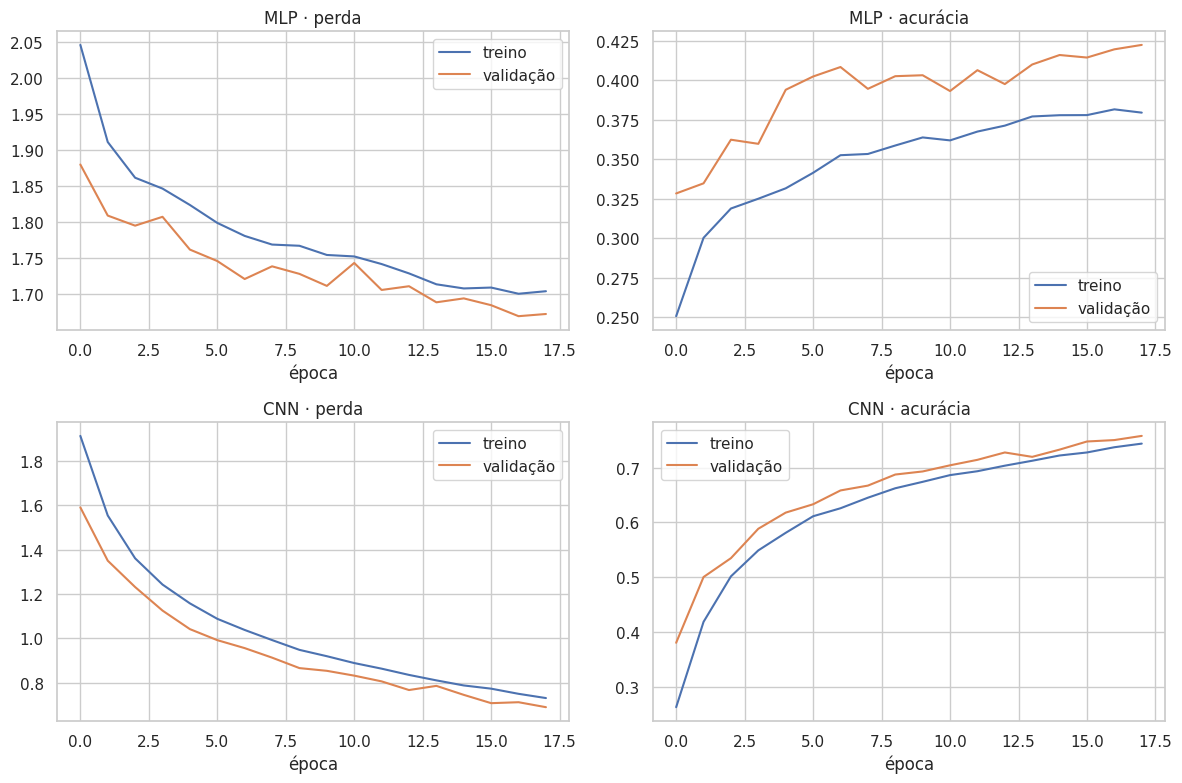

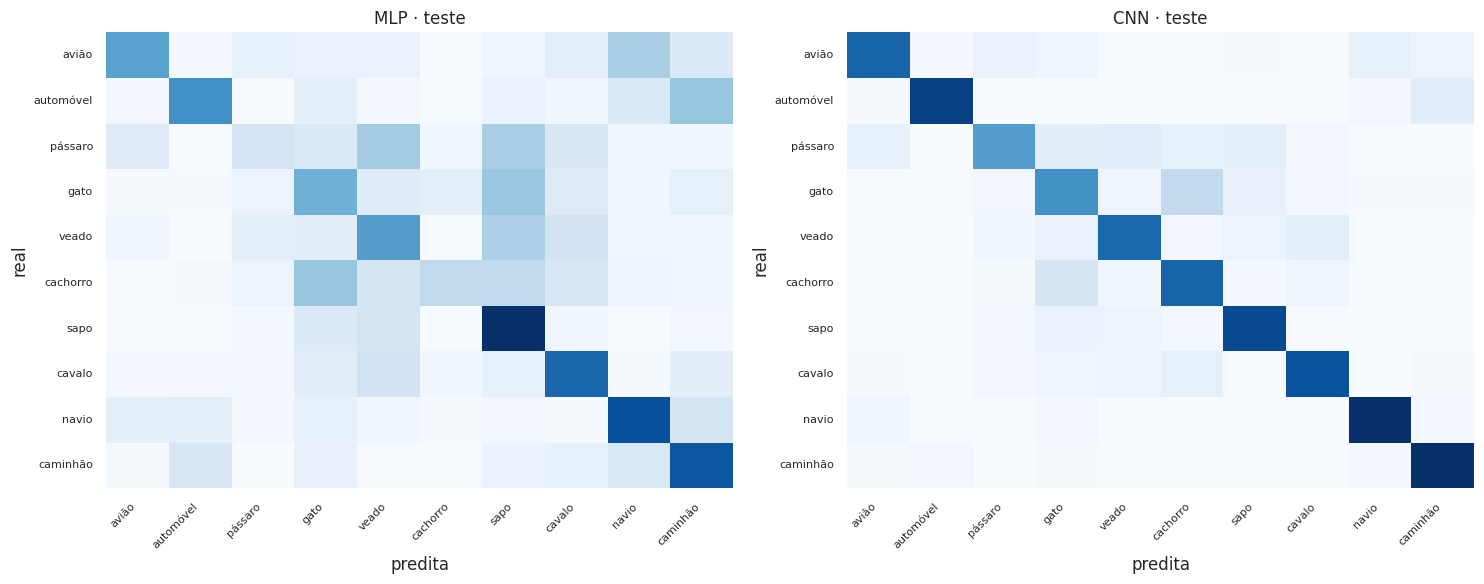

In [4]:
EPOCAS_CIFAR=18 if MODO_EXECUCAO=="completo" else 4
hist_mlp=modelo_mlp.fit(Xc_tr,yc_tr,validation_data=(Xc_va,yc_va),epochs=EPOCAS_CIFAR,batch_size=128,callbacks=callbacks_img,verbose=1)
hist_cnn=modelo_cnn.fit(Xc_tr,yc_tr,validation_data=(Xc_va,yc_va),epochs=EPOCAS_CIFAR,batch_size=128,callbacks=callbacks_img,verbose=1)
_,acc_mlp=modelo_mlp.evaluate(Xc_te,yc_te,verbose=0); _,acc_cnn=modelo_cnn.evaluate(Xc_te,yc_te,verbose=0)
print(f"Acurácia teste — MLP: {acc_mlp:.4f} | CNN: {acc_cnn:.4f}")
fig,axs=plt.subplots(2,2,figsize=(12,8))
for ax,h,met,t in [(axs[0,0],hist_mlp,"loss","MLP · perda"),(axs[0,1],hist_mlp,"accuracy","MLP · acurácia"),(axs[1,0],hist_cnn,"loss","CNN · perda"),(axs[1,1],hist_cnn,"accuracy","CNN · acurácia")]:
    ax.plot(h.history[met],label="treino"); ax.plot(h.history["val_"+met],label="validação"); ax.set(title=t,xlabel="época"); ax.legend()
plt.tight_layout(); plt.show()
pred_mlp=modelo_mlp.predict(Xc_te,batch_size=256,verbose=0).argmax(axis=1); pred_cnn=modelo_cnn.predict(Xc_te,batch_size=256,verbose=0).argmax(axis=1)
fig,axs=plt.subplots(1,2,figsize=(15,6))
for ax,p,t in [(axs[0],pred_mlp,"MLP"),(axs[1],pred_cnn,"CNN")]:
    sns.heatmap(confusion_matrix(yc_te,p),cmap="Blues",ax=ax,cbar=False); ax.set(title=t+" · teste",xlabel="predita",ylabel="real")
    ax.set_xticklabels(nomes_cifar,rotation=45,ha="right",fontsize=8); ax.set_yticklabels(nomes_cifar,rotation=0,fontsize=8)
plt.tight_layout(); plt.show()

# Questão 4 — Representações aprendidas pela CNN

Filtros iniciais podem parecer detectores de cor/contorno; ativações mostram onde um canal respondeu. Ativação alta isolada não prova importância causal. Acrescentamos Grad-CAM, que pondera mapas da última convolução pelos gradientes do score previsto. É uma explicação aproximada e de resolução baixa.

### Q4a — leitura da célula: visualizar os pesos dos filtros

Recuperamos os pesos da primeira convolução `conv1`, cujo formato é **(3,3,3,32)**: altura, largura, canais RGB de entrada e 32 filtros de saída. Cada painel mostra um filtro 3×3 com três canais. Os pesos são os mesmos para toda imagem; não dependem de qual exemplo está sendo mostrado.

Cada filtro é normalizado individualmente para [0,1] apenas para desenhá-lo. Isso não altera os pesos do modelo, mas impede comparar sua magnitude absoluta pela intensidade de painéis diferentes. O grid mostra combinações locais de cor e contraste, não imagens semânticas de objetos. Um kernel colorido pode sugerir sensibilidade a transições, mas sua função deve ser investigada também pelas respostas a imagens.

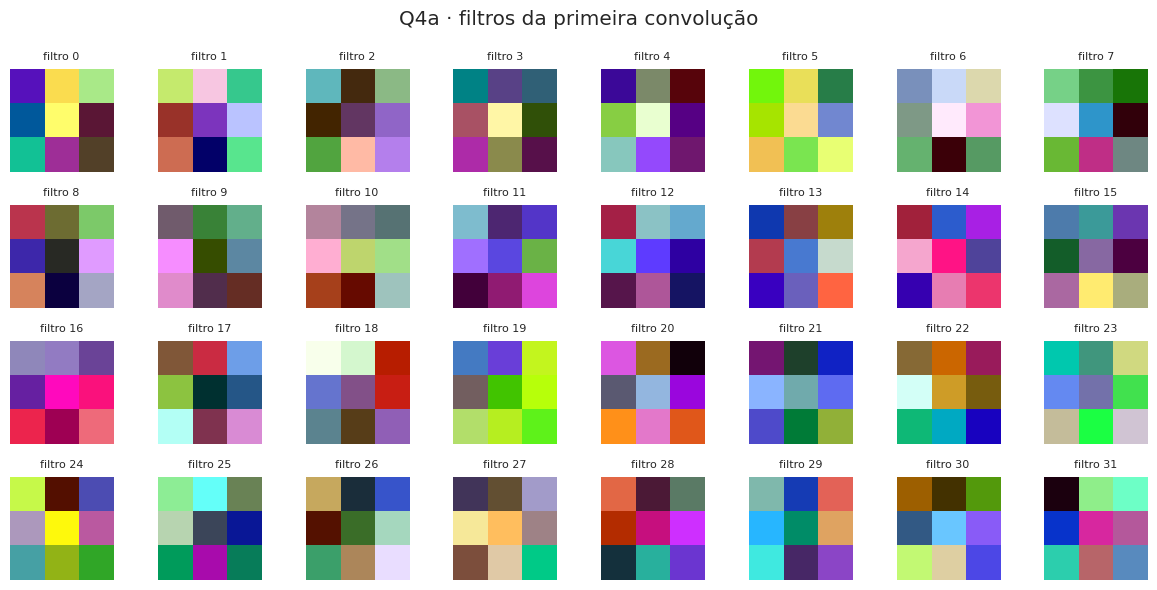

Formato dos kernels: (3, 3, 3, 32)


In [5]:
kernels=modelo_cnn.get_layer("conv1").get_weights()[0]
nf=kernels.shape[-1]; cols=8; rows=int(np.ceil(nf/cols)); fig,axs=plt.subplots(rows,cols,figsize=(cols*1.5,rows*1.5))
for i,ax in enumerate(np.array(axs).reshape(-1)):
    if i<nf:
        k=kernels[:,:,:,i]; k=(k-k.min())/(k.max()-k.min()+1e-8); ax.imshow(k); ax.set_title(f"filtro {i}",fontsize=8)
    ax.axis("off")
fig.suptitle("Q4a · filtros da primeira convolução"); plt.tight_layout(); plt.show()
print("Formato dos kernels:",kernels.shape)

## Q4b — Mapas de ativação intermediários

Exibimos oito canais reais da camada `conv2` para cinco imagens de teste. Cada painel mostra uma resposta interna; os mapas não são, por si só, explicações causais. Grad-CAM completa a inspeção com uma localização aproximada da evidência associada à classe predita.


### Q4b — leitura da célula: de pesos fixos a respostas dependentes da imagem

Selecionamos cinco índices igualmente espaçados no teste: 0, 2499, 4999, 7499 e 9999. Essa regra é determinística e não escolhe os exemplos com base no resultado. Ela não garante uma imagem por classe ou representatividade estatística.

Um modelo intermediário liga a entrada da CNN à saída de `conv2`. Nessa camada, cada imagem produz **16×16×64** ativações: a resolução já foi reduzida pelo primeiro pooling. Exibimos os oito primeiros canais, 0 a 7, sem afirmar que sejam os mais importantes. A primeira coluna contém a imagem e as seguintes mostram as respostas internas.

ReLU torna ativações não negativas. Cores intensas indicam maior resposta dentro da escala daquele painel; como `imshow` ajusta escalas automaticamente, não se deve comparar brilho absoluto entre mapas diferentes. Respostas podem cobrir o objeto, bordas ou fundo. A resolução 16×16 também limita a precisão de localização.

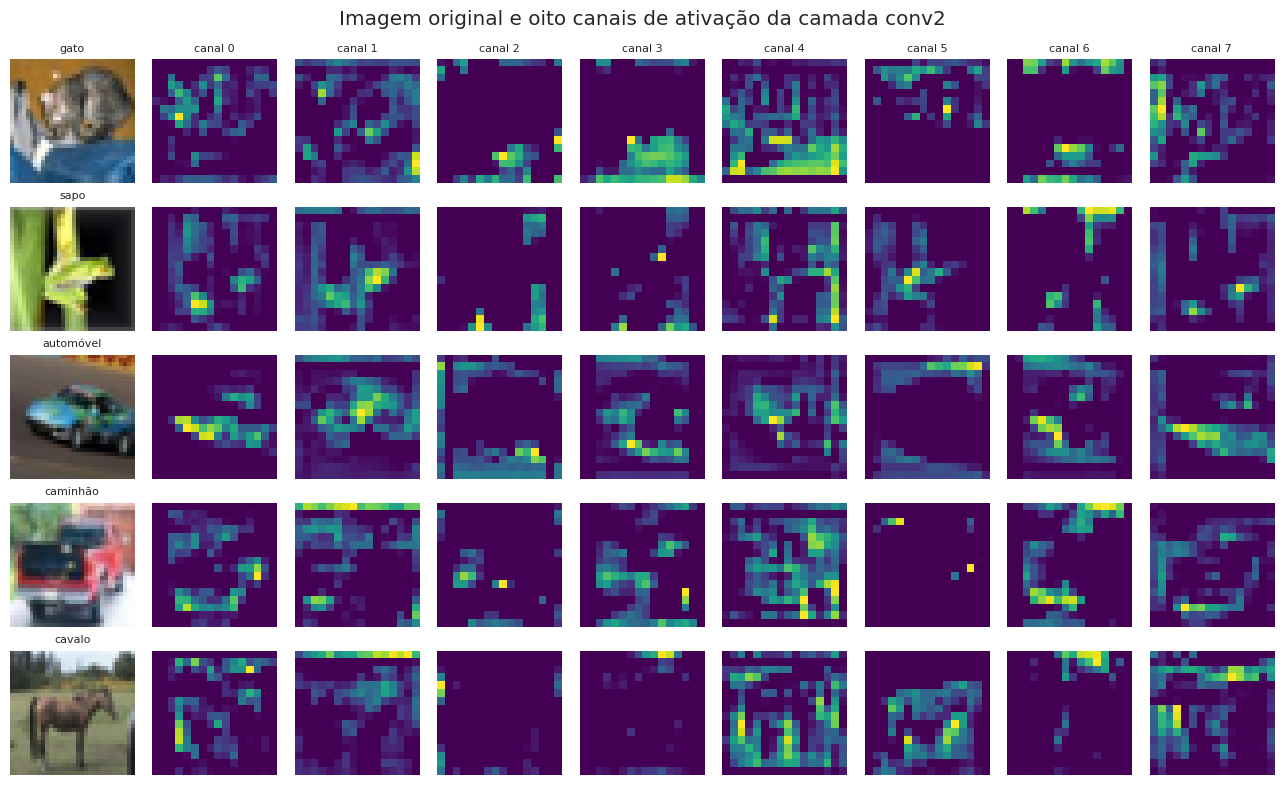

In [6]:
indices_q4 = np.linspace(0, len(Xc_te) - 1, 5, dtype=int)
camada_ativ=keras.Model(modelo_cnn.input,modelo_cnn.get_layer("conv2").output)
fig,axs=plt.subplots(5,9,figsize=(13,8))
for r,idx in enumerate(indices_q4):
    mapas=camada_ativ.predict(Xc_te[idx:idx+1],verbose=0)[0]
    axs[r,0].imshow(Xc_te[idx]); axs[r,0].set_title(nomes_cifar[yc_te[idx]],fontsize=8); axs[r,0].axis("off")
    for j in range(8): axs[r,j+1].imshow(mapas[:,:,j],cmap="viridis"); axs[r,j+1].axis("off")
for j in range(1,9): axs[0,j].set_title(f"canal {j-1}",fontsize=8)
plt.suptitle("Imagem original e oito canais de ativação da camada conv2"); plt.tight_layout(); plt.show()

### Q4b — leitura da célula: Grad-CAM e as três maiores saídas

Grad-CAM é uma técnica adicional de inspeção: usa gradientes para ponderar os mapas da última convolução (`conv3`, com resolução 8×8 e 128 canais). Aqui o escore diferenciado é a **saída Softmax da classe prevista**, não o logit antes da Softmax. Saturação da probabilidade e escolha do escore podem afetar os gradientes.

O procedimento é: executar a imagem em modo de inferência; escolher a classe prevista; calcular o gradiente de seu escore em relação aos mapas; tirar a média espacial desses gradientes para obter pesos dos canais; somar os mapas ponderados; manter valores positivos; normalizar e ampliar 8×8 para 32×32. Essa ampliação facilita sobrepor, sem recuperar detalhes que o mapa original não contém. Dropout permanece desligado (`training=False`).

Cada linha mostra imagem original, sobreposição e as três maiores saídas. O mapa se refere à previsão da rede, mesmo quando ela está errada. Cores quentes indicam contribuição positiva segundo essa aproximação, não uma segmentação do objeto ou uma prova causal. Os valores do gráfico não foram calibrados como probabilidades confiáveis.

Se o mapa for quase nulo, a normalização com pequena constante evita divisão por zero; isso não significa ausência comprovada de informação naquela região. Diferentes escalas e a interpolação exigem leitura qualitativa cautelosa.

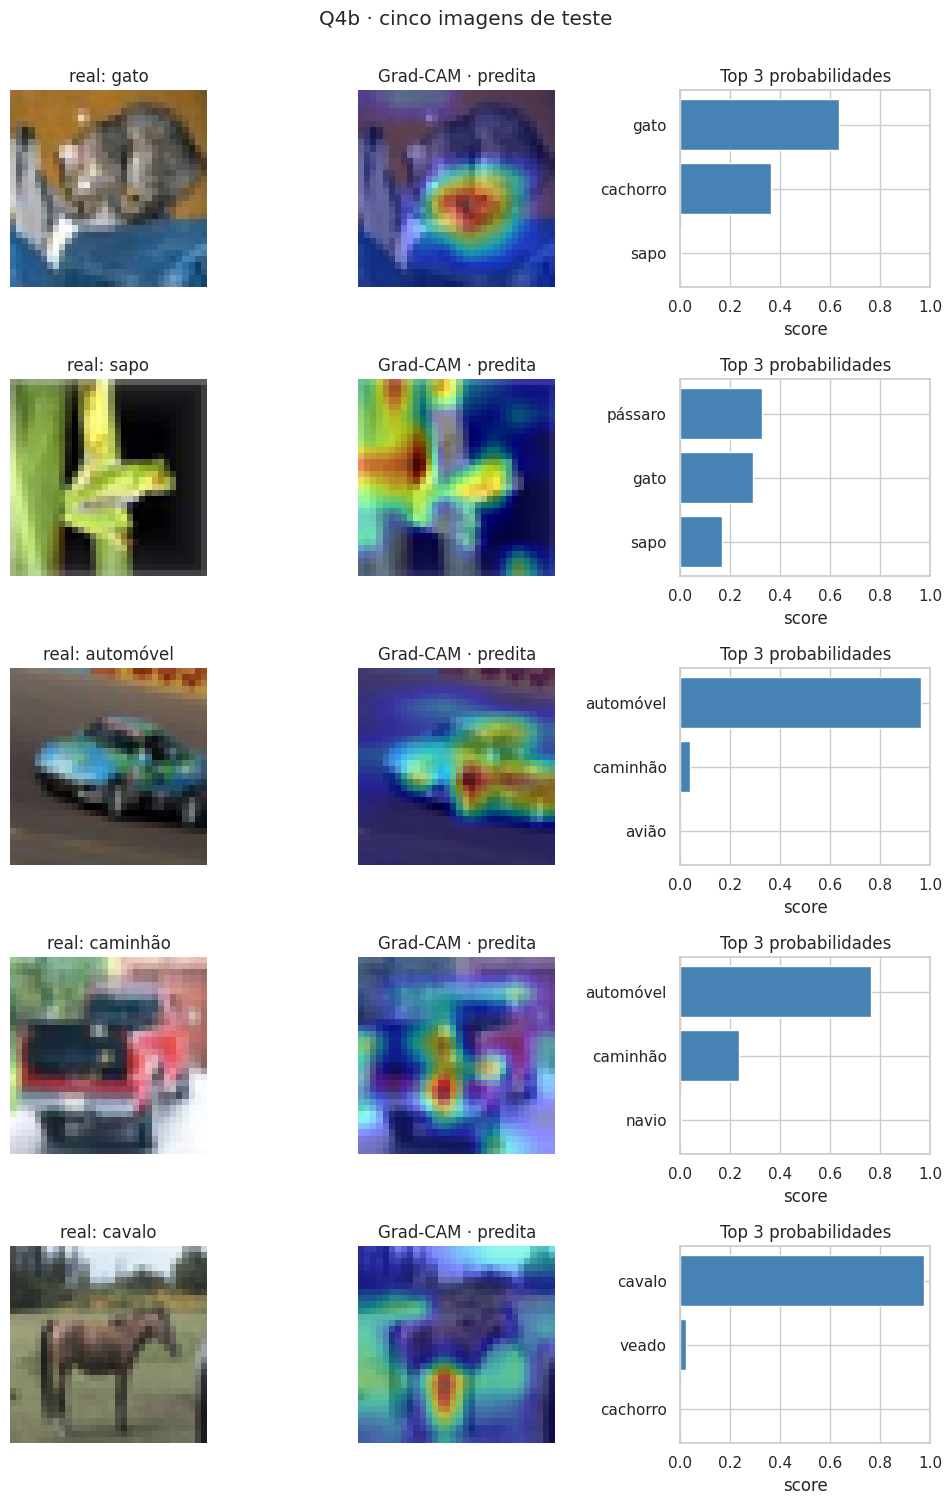

In [7]:
def gradcam(imagem,classe=None):
    conv=modelo_cnn.get_layer("conv3"); extrator=keras.Model(modelo_cnn.inputs,[conv.output,modelo_cnn.output])
    with tf.GradientTape() as tape:
        ativ,prob=extrator([imagem[None,...]],training=False)
        if classe is None: classe=tf.argmax(prob[0])
        score=prob[:,classe]
    grad=tape.gradient(score,ativ); pesos=tf.reduce_mean(grad,axis=(1,2),keepdims=True)
    mapa=tf.maximum(tf.reduce_sum(pesos*ativ,axis=-1)[0],0); mapa/=tf.reduce_max(mapa)+1e-8
    mapa=tf.image.resize(mapa[...,None],(32,32)).numpy().squeeze()
    return mapa,prob.numpy()[0],int(classe)
indices_q4=np.linspace(0,len(Xc_te)-1,5,dtype=int); fig,axs=plt.subplots(5,3,figsize=(10,15))
for r,idx in enumerate(indices_q4):
    img=Xc_te[idx]; mapa,prob,c=gradcam(img)
    axs[r,0].imshow(img); axs[r,0].set_title("real: "+nomes_cifar[yc_te[idx]])
    axs[r,1].imshow(img); axs[r,1].imshow(mapa,cmap="jet",alpha=.45); axs[r,1].set_title("Grad-CAM · predita")
    top3=np.argsort(prob)[-3:][::-1]
    ordem=top3[::-1]
    axs[r,2].barh([nomes_cifar[k] for k in ordem],prob[ordem],color="steelblue")
    axs[r,2].set_xlim(0,1); axs[r,2].set_title("Top 3 probabilidades"); axs[r,2].set_xlabel("score")
    axs[r,0].axis("off"); axs[r,1].axis("off")
plt.suptitle("Q4b · cinco imagens de teste",y=1.002); plt.tight_layout(); plt.show()

### Leitura qualitativa dos exemplos preservados

Os filtros iniciais aparecem como pequenos padrões de cor e contraste. Nos mapas intermediários, respostas esparsas ou intensas aparecem tanto no objeto como em partes do fundo. Esses resultados são compatíveis com extração de padrões locais, sem identificar uma função semântica exclusiva para cada canal.

No Grad-CAM do **gato** corretamente classificado (escore aproximadamente 0,63), o calor se concentra no centro, sobre o corpo, sem estar claramente restrito ao rosto. No **automóvel** correto (aproximadamente 0,96), aparece na metade direita, na região de cabine/traseira. O **cavalo** foi classificado corretamente com escore aproximadamente 0,98. O **sapo** foi previsto como pássaro (aproximadamente 0,33), e o **caminhão** como automóvel (aproximadamente 0,76). Os erros permitem levantar a hipótese de pistas compartilhadas ou de contexto; o mapa não comprova essa causa.

Estas descrições acompanham as figuras salvas. Se a CNN for retreinada, a seleção de índices permanece, mas os mapas, classes previstas e escores podem mudar e precisam ser lidos novamente. Não atribuímos causalidade a regiões quentes nem inferimos erro de rótulo apenas pela aparência.

### Q4c — leitura da célula: selecionar acertos e erros sem confundir confiança com correção

Calculamos a Softmax no teste, escolhemos a classe de maior saída e guardamos esse maior escore como confiança operacional. A figura usa **os primeiros quatro acertos e os primeiros quatro erros na ordem do conjunto**, não os erros mais confiantes. Essa seleção serve para ilustrar e não estimar a distribuição de todos os erros.

O título de cada painel informa o status, a classe real, a prevista e o escore. Foram **7.456 acertos e 2.544 erros** em 10.000 imagens, coerentes com a accuracy 74,56% da Q3. Esses totais são globais; a figura exibe apenas oito exemplos.

Um erro com escore alto expõe que confiança Softmax e acerto são propriedades distintas. Sem auditoria adicional, uma imagem ambígua não autoriza afirmar que o rótulo da base esteja errado. A próxima investigação poderia examinar padrões por classe ou calibração, mas essas análises não foram executadas aqui.

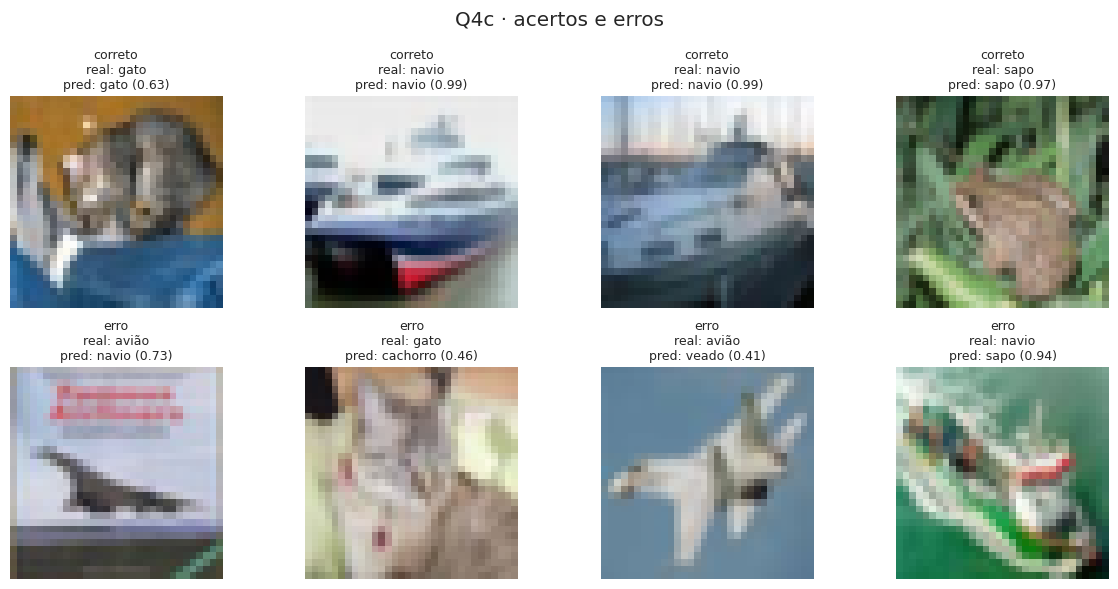

Corretos: 7456 | erros: 2544


In [8]:
proba_cnn=modelo_cnn.predict(Xc_te,batch_size=256,verbose=0); pred_cnn=proba_cnn.argmax(axis=1); confianca=proba_cnn.max(axis=1)
certos=np.where(pred_cnn==yc_te)[0]; erros=np.where(pred_cnn!=yc_te)[0]; sel=np.concatenate([certos[:4],erros[:4]])
fig,axs=plt.subplots(2,4,figsize=(12,6))
for ax,idx in zip(axs.flat,sel):
    ax.imshow(Xc_te[idx]); ax.axis("off"); status="correto" if pred_cnn[idx]==yc_te[idx] else "erro"
    ax.set_title(f"{status}\nreal: {nomes_cifar[yc_te[idx]]}\npred: {nomes_cifar[pred_cnn[idx]]} ({confianca[idx]:.2f})",fontsize=9)
plt.suptitle("Q4c · acertos e erros"); plt.tight_layout(); plt.show(); print("Corretos:",len(certos),"| erros:",len(erros))

## Conclusão da Q4 e relação com os requisitos

| Parte | Produto apresentado | Interpretação correta |
|---|---|---|
| Q4a | 32 filtros 3×3×3 da primeira convolução | Pesos aprendidos, visualizados após normalização |
| Q4b | Oito canais de conv2 em cinco imagens | Respostas internas em resolução 16×16 |
| Complemento Q4b | Grad-CAM e três maiores saídas | Localização aproximada associada à classe prevista |
| Q4c | Quatro acertos e quatro erros, com escores | Exemplos ilustrativos; 7.456 acertos globais no teste |

As três inspeções se complementam: filtros mostram parâmetros, ativações mostram respostas e Grad-CAM relaciona mapas a um escore. Nenhuma delas, isoladamente, prova uma explicação causal ou representa todos os exemplos. A seleção de cinco imagens e oito canais é um recorte explícito. O teste usado para ilustrar não deve passar a orientar repetidamente escolhas de arquitetura sem nova avaliação independente.

**Perguntas frequentes:** “Por que não usar outra CNN na Q4?” Porque analisar a rede da Q3 mantém vínculo entre desempenho e representações. “O mapa marca o objeto?” Ele não foi treinado como segmentação. “Uma probabilidade alta garante acerto?” Não, e a calibração não foi medida. “Uma ativação apagada significa neurônio inútil?” Não; ela descreve apenas a entrada e o canal exibidos.

## Referências de apoio

- CIFAR-10, origem e classes: https://www.cs.toronto.edu/~kriz/cifar.html
- Keras, conjunto CIFAR-10: https://keras.io/api/datasets/cifar10/
- Keras, convolução 2D: https://keras.io/api/layers/convolution_layers/convolution2d/
- Keras, dropout: https://keras.io/api/layers/regularization_layers/dropout/
- Keras, exemplo de Grad-CAM: https://keras.io/examples/vision/grad_cam/

Esses materiais ajudam a consultar os conceitos. Os resultados e figuras relatados são os da execução preservada, com as escolhas específicas descritas nas células.